# RevIN — *Reversible Instance Normalization* para previsão de séries temporais

**Um guia executável: teoria, implementação em PyTorch e o efeito medido com dados sintéticos.**

---

## O que você vai aprender

1. Por que um modelo de previsão treinado em um regime de mercado "quebra" quando o nível e a escala da série mudam.
2. Como o RevIN resolve isso normalizando **cada janela de entrada** por conta própria e devolvendo a previsão à escala original.
3. Como implementar a camada em ~30 linhas de PyTorch, com o inverso exato e testável.
4. O quanto isso muda o erro, medido em um experimento reprodutível, comparando **sem normalização × normalização global × RevIN** em duas arquiteturas.
5. Um resultado contraintuitivo que vale o preço do notebook: **o RevIN não ajuda todo mundo igualmente**. Uma MLP quase não sofre com o shift e uma GRU colapsa. Entender *por quê* é o que separa "usar a camada" de "saber quando ela importa".
6. As armadilhas que fazem a maior parte das implementações de RevIN falhar em silêncio.

## Pré-requisitos

`torch`, `numpy`, `pandas`, `matplotlib`. Roda em CPU em poucos minutos. Nenhum dado externo é baixado — a série é gerada aqui, com semente fixa.

## Um aviso sobre o nome

"Instance Normalization" aqui não é a InstanceNorm de visão computacional. Na visão, normaliza-se por canal ao longo de (H, W) **dentro de um batch**. Em séries temporais, normaliza-se cada **amostra** ao longo do **eixo do tempo**, usando apenas a janela de entrada daquela amostra. O nome vem da ideia de "instância = uma janela", e é o que torna a operação reversível sem vazar informação do futuro.

## 1. O problema: o mundo não fica parado

Um modelo de previsão aprende um mapeamento

$$\hat{y}_{t+1:t+H} = f_\theta(x_{t-L+1:t})$$

Supõe-se, implicitamente, que a distribuição dos dados no momento da previsão é a mesma do treino. Em séries econômicas e de demanda isso raramente vale. Dois tipos de deslocamento aparecem o tempo todo:

| Tipo | O que muda | Exemplo |
|---|---|---|
| **Mudança de nível** ($\mu$) | o patamar da série | demanda que não volta ao patamar pré-crise; preço após mudança de política |
| **Mudança de escala** ($\sigma$) | a amplitude das flutuações | período de volatilidade cambial: mesma forma, oscilações 2× maiores |

Formalmente, se a série passa por uma transformação afim

$$y^{\text{novo}} = a \, y^{\text{antigo}} + b, \qquad a > 0$$

o modelo antigo não tem como saber disso: ele continua prevendo na faixa de valores em que foi treinado. O erro não é ruído — é **viés sistemático**, e cresce com o horizonte. Nenhuma quantidade de camadas resolve, porque o problema está na entrada, não na capacidade do modelo.

> **Regra prática:** se o MAE do seu modelo em produção é aproximadamente proporcional ao deslocamento de nível da série, você tem um problema de normalização, não de arquitetura.

## 2. A ideia do RevIN: três passos

Para cada janela de entrada $x_{1:L}$ (uma "instância"), calcule duas estatísticas **somente sobre ela**:

$$\mu = \frac{1}{L}\sum_{i=1}^{L} x_i, \qquad \sigma = \sqrt{\frac{1}{L}\sum_{i=1}^{L}(x_i - \mu)^2 + \varepsilon}$$

**Passo 1 — normalizar** (opcionalmente com uma transformação afim aprendível, por canal):

$$\tilde{x}_i = \gamma \cdot \frac{x_i - \mu}{\sigma} + \beta$$

**Passo 2 — prever no espaço normalizado.** O modelo $f_\theta$ nunca vê o nível original; ele vê uma série com média 0 e variância 1. Aprende *forma*, não *magnitude*.

**Passo 3 — desnormalizar** a saída, invertendo na ordem inversa:

$$\hat{y}_j = \sigma \cdot \frac{\hat{y}^{\text{norm}}_j - \beta}{\gamma} + \mu$$

O ponto central, fácil de perder: **as mesmas** $\mu$ e $\sigma$ da janela de entrada trazem a previsão de volta. Se a série mudou de patamar, a janela de entrada já está no patamar novo; $\mu$ acompanha; a previsão sai no patamar certo. O modelo não precisa extrapolar nada.

### Por que "reversível" é a palavra importante

Uma normalização só é útil para previsão se você souber voltar. Compare as alternativas:

| Abordagem | Estatísticas vêm de | É reversível? | Sob mudança de regime |
|---|---|---|---|
| Sem normalização | — | — | depende da arquitetura (voltamos a isso na seção 7) |
| **Normalização global** (z-score/min-max do treino) | todo o conjunto de treino | sim, mas com estatísticas **congeladas** | prevê na faixa antiga |
| Min-max por janela (comum em ML) | a janela | só se você guardar min/max de cada janela e reescalar | funciona, mas exige código manual em todo lugar |
| BatchNorm / InstanceNorm de visão | o batch, por canal | depende do batch em inferência | vaza estatística entre amostras e quebra com batch=1 |
| **RevIN** | **a janela, e o inverso é parte do módulo** | **sim, exato e encapsulado** | **acompanha o regime** |

O RevIN é a formalização de algo que bons praticantes já faziam à mão, com duas adições: a transformação afim aprendível e o encapsulamento que impede vazamento de futuro.

> Referência: Kim et al., *Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift*, ICLR 2022.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

C_TREINO, C_TESTE, C_REVIN, C_CINZA = "#1f77b4", "#d62728", "#2ca02c", "#7f7f7f"

print("torch:", torch.__version__, "| numpy:", np.__version__)

torch: 2.4.1+cu121 | numpy: 1.26.4


## 3. Dados fictícios, com o shift que interessa

Não vou usar uma série real, porque quero **controlar** o tipo de deslocamento e poder medir o efeito. A série é a soma de quatro componentes:

$$s(t) = \underbrace{\mu_{\text{reg}}}_{\text{nível}} + \underbrace{\beta_{\text{reg}}\, t}_{\text{tendência}} + \underbrace{A_{\text{reg}}\sin\!\left(\frac{2\pi t}{52}\right) + 0{,}4 A_{\text{reg}}\sin\!\left(\frac{2\pi t}{26} + \phi\right)}_{\text{sazonalidade anual + harmônico}} + \underbrace{\varepsilon_t}_{\text{ruído}}$$

Regime **A** (treino): nível 10, amplitude 1,0, ruído $\mathcal{N}(0;\, 0{,}30)$.

Regime **B** (teste): nível 16, amplitude 1,7, ruído $\mathcal{N}(0;\, 0{,}55)$, pequena defasagem de fase.

Ou seja: **+60% de nível, +70% de amplitude, forma quase igual**. É o cenário que o RevIN deveria resolver — e o teste de estresse de um previsor treinado no regime A.

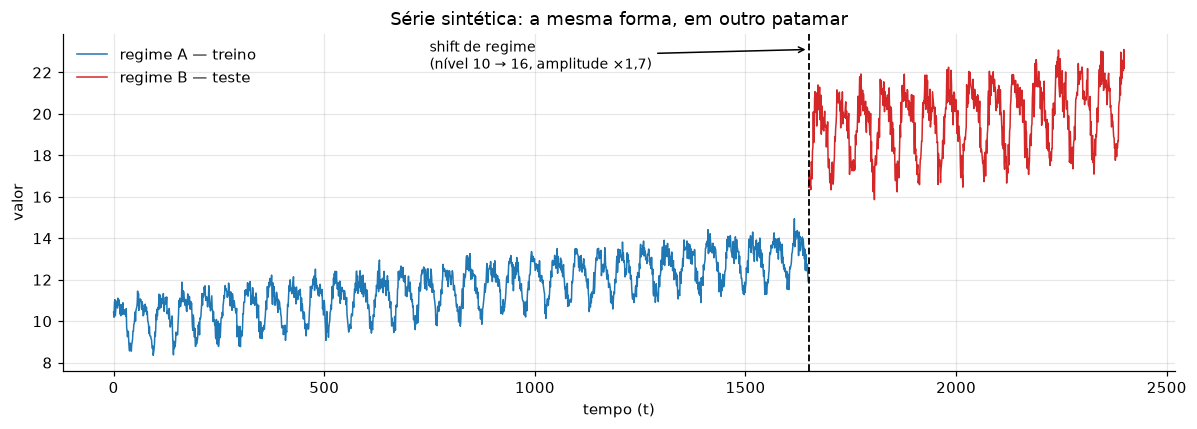

média regime A:  11.65   desvio:  1.25
média regime B:  19.78   desvio:  1.53


In [2]:
N = 2400          # pontos
T0 = 1650         # índice em que o regime B começa
t = np.arange(N, dtype=float)


def make_serie(nivel_b=16.0, amp_b=1.7, sigma_b=0.55, seed=SEED):
    """Gera a série: regime A sempre igual, regime B parametrizável.

    Usa um gerador local para que o regime A (treino) seja idêntico entre
    chamadas — sem isso, o sweep confundiria o efeito do shift com o de
    uma nova amostra de ruído.
    """
    g = np.random.default_rng(seed)
    s = (10.0
         + 0.002 * t
         + 1.0 * np.sin(2 * np.pi * t / 52)
         + 0.4 * np.sin(2 * np.pi * t / 26 + 1.0)
         + g.normal(0, 0.30, N))
    s[T0:] = (nivel_b
              + 0.002 * (t[T0:] - T0) + 3.0
              + amp_b * np.sin(2 * np.pi * t[T0:] / 52 + 0.25)
              + 0.4 * amp_b * np.sin(2 * np.pi * t[T0:] / 26 + 1.35)
              + g.normal(0, sigma_b, N - T0))
    return s


serie = make_serie()

fig, ax = plt.subplots()
ax.plot(t[:T0], serie[:T0], color=C_TREINO, lw=1.0, label="regime A — treino")
ax.plot(t[T0:], serie[T0:], color=C_TESTE, lw=1.0, label="regime B — teste")
ax.axvline(T0, color="k", ls="--", lw=1.2)
ax.annotate("shift de regime\n(nível 10 → 16, amplitude ×1,7)",
            xy=(T0, serie[T0:] .max()),
            xytext=(T0 - 900, serie[T0:].max() * 0.96),
            arrowprops=dict(arrowstyle="->", lw=1.0), fontsize=9)
ax.set_title("Série sintética: a mesma forma, em outro patamar")
ax.set_xlabel("tempo (t)")
ax.set_ylabel("valor")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

print(f"média regime A: {serie[:T0].mean():6.2f}   desvio: {serie[:T0].std():5.2f}")
print(f"média regime B: {serie[T0:].mean():6.2f}   desvio: {serie[T0:].std():5.2f}")

### Janelas deslizantes

Todo previsor multi-passo consome pares entrada/saída. Com `lookback = 32` e `horizon = 12`:

* **entrada** — 32 observações consecutivas ($x_{e-32:e}$)
* **alvo** — as 12 observações seguintes ($y_{e:e+12}$)

As janelas de treino terminam **antes** de `T0`; as de teste começam **depois** de `T0`. Isso é obrigatório: uma janela que atravessa a fronteira ensinaria o regime novo ao modelo e o experimento perderia o sentido.

In [ ]:
LOOKBACK, HORIZON = 32, 12


def build_windows(series, ends, lookback=LOOKBACK, horizon=HORIZON):
    """Constrói tensores (N, L, 1) de entrada e (N, H, 1) de alvo."""
    X = np.stack([series[e - lookback:e] for e in ends])
    Y = np.stack([series[e:e + horizon] for e in ends])
    X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
    Y = torch.tensor(Y, dtype=torch.float32).unsqueeze(-1)
    return X, Y
  

train_ends = np.arange(LOOKBACK, T0 - HORIZON)
test_ends = np.arange(T0, N - HORIZON)

X_train, Y_train = build_windows(serie, train_ends)
X_test, Y_test = build_windows(serie, test_ends)

print(f"janelas de treino: {len(X_train)}  ->  X {tuple(X_train.shape)}  Y {tuple(Y_train.shape)}")
print(f"janelas de teste : {len(X_test)}  ->  X {tuple(X_test.shape)}  Y {tuple(Y_test.shape)}")
print(f"\nfaixa do treino: [{serie[:T0].min():.2f}, {serie[:T0].max():.2f}]")
print(f"faixa do teste : [{serie[T0:].min():.2f}, {serie[T0:].max():.2f}]  <- fora da faixa vista no treino")

janelas de treino: 1606  ->  X (1606, 32, 1)  Y (1606, 12, 1)
janelas de teste : 738  ->  X (738, 32, 1)  Y (738, 12, 1)

faixa do treino: [8.35, 14.94]
faixa do teste : [15.86, 23.11]  <- fora da faixa vista no treino


## 4. A camada RevIN

A implementação tem quatro decisões que valem comentário, porque é onde os bugs moram.

**a) O eixo das estatísticas.** Com entrada `(B, L, C)` (batch, tempo, canais), as estatísticas percorrem `dim=1` e ficam com formato `(B, 1, C)`. Cada amostra do batch tem sua própria média e seu próprio desvio. Se você usar `dim=0`, está calculando estatísticas do *batch* — outra coisa, e a errada aqui.

**b) `sqrt(var + eps)`, variância enviesada (`unbiased=False`).** O `eps` protege séries constantes (demanda travada, sensor com defeito). Sem ele você divide por zero em silêncio.

**c) As estatísticas são `detach()`.** São tratadas como constantes, não como função dos parâmetros — é o que o artigo faz e é o comportamento seguro: deixar o gradiente fluir por $\mu$ e $\sigma$ permite ao otimizador "enganar" a normalização em vez de aprender o padrão.

**d) `denormalize` usa as estatísticas da última chamada a `normalize`.** Por isso a classe guarda `self._mean` / `self._std` como estado. Consequência prática: chame `normalize` antes de `denormalize` e não compartilhe a mesma instância entre forward passes concorrentes.

O `gamma`/`beta` começam na identidade ($\gamma=1, \beta=0$), então o módulo **começa** como uma normalização simples e só se afasta dela se isso reduzir a perda.

In [4]:
class RevIN(nn.Module):
    """Reversible Instance Normalization (Kim et al., ICLR 2022).

    Normaliza cada amostra ao longo do eixo do tempo, usando estatísticas
    apenas da janela de entrada, e oferece o inverso exato.

    Entrada/saída: (B, L, C)  — batch, tempo, canais.
    """

    def __init__(self, num_features: int, eps: float = 1e-5, affine: bool = True):
        super().__init__()
        self.num_features = num_features
        self.eps = eps
        self.affine = affine
        if affine:
            self.gamma = nn.Parameter(torch.ones(1, 1, num_features))
            self.beta = nn.Parameter(torch.zeros(1, 1, num_features))
        self._mean = None
        self._std = None

    def normalize(self, x: torch.Tensor) -> torch.Tensor:
        # estatísticas POR AMOSTRA, ao longo do tempo (dim=1), sem gradiente
        self._mean = x.mean(dim=1, keepdim=True).detach()
        self._std = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
        x = (x - self._mean) / self._std
        if self.affine:
            x = x * self.gamma + self.beta
        return x

    def denormalize(self, x: torch.Tensor) -> torch.Tensor:
        if self._mean is None:
            raise RuntimeError("chame normalize() antes de denormalize()")
        if self.affine:
            x = (x - self.beta) / self.gamma      # desfaz o afim primeiro
        return x * self._std + self._mean         # depois desfaz escala e nível

    def extra_repr(self) -> str:
        return f"num_features={self.num_features}, eps={self.eps}, affine={self.affine}"

### Dois testes que provam que o inverso está certo

Antes de plugar em qualquer modelo, verifique a álgebra. São dois testes de dez segundos que economizam horas de depuração.

**Teste 1 — identidade:** `denormalize(normalize(x))` deve devolver `x`.

**Teste 2 — invariância a transformação afim:** se você multiplicar a janela por 3,5 e somar 12, a versão *normalizada* deve permanecer praticamente a mesma. É exatamente a propriedade que faz o modelo sobreviver a uma mudança de patamar — e ela mostra, numericamente, que o modelo vê a mesma entrada em dois regimes de mercado completamente diferentes.

In [5]:
torch.manual_seed(0)
x = torch.randn(4, 32, 1) * 3.0 + 7.0     # 4 janelas, 32 passos, 1 canal

revin = RevIN(num_features=1, affine=True)
z = revin.normalize(x)
x_rec = revin.denormalize(z)

print("== Teste 1: identidade ==")
print(f"erro máximo de reconstrução : {(x - x_rec).abs().max().item():.3e}")
print(f"média após normalizar       : {z.mean(dim=1).abs().max().item():.3e}  (esperado ~0)")
print(f"desvio após normalizar      : {[round(v, 6) for v in z.std(dim=1, unbiased=False).flatten().tolist()]}")

print("\n== Teste 2: invariância a transformação afim ==")
x2 = 3.5 * x + 12.0                        # outra escala, outro nível
z2 = revin.normalize(x2)
print(f"nível médio antes  : {x.mean().item():7.3f} -> depois: {x2.mean().item():7.3f}")
print(f"distância entre as duas versões normalizadas: {(z - z2).abs().mean().item():.3e}")

print("\n== O que a desnormalização faz com uma previsão constante ==")
janela = x2[:1]                            # uma janela só, para as estatísticas ficarem (1,1,1)
revin.normalize(janela)
const = torch.zeros(1, 1, 1)               # previsão "0" no espaço normalizado
print(f"0 normalizado, na escala original da janela: {revin.denormalize(const).item():.3f}")
print(f"(é a média daquela janela: {janela.mean().item():.3f})")

== Teste 1: identidade ==
erro máximo de reconstrução : 4.768e-07
média após normalizar       : 1.043e-07  (esperado ~0)
desvio após normalizar      : [0.999999, 1.0, 1.0, 1.0]

== Teste 2: invariância a transformação afim ==
nível médio antes  :   7.157 -> depois:  37.051
distância entre as duas versões normalizadas: 3.940e-07

== O que a desnormalização faz com uma previsão constante ==
0 normalizado, na escala original da janela: 36.569
(é a média daquela janela: 36.569)


## 5. Dois modelos, e uma hipótese a testar

Para isolar o efeito da normalização, nada de atenção: duas arquiteturas simples, ambas mapeando a janela de $L$ passos nos $H$ passos do horizonte.

**a) `MLPForecaster`** — janela achatada entra numa rede feedforward com ReLU. Sem memória, sem recorrência.

**b) `GRUForecaster`** — a mesma janela vira uma sequência para uma GRU; o último estado oculto gera os $H$ passos.

São propositalmente parecidas em tamanho e diferentes em um aspecto crucial: a GRU usa `tanh`/`sigmoid`, que são **funções limitadas**. Uma MLP com ReLU e saída linear é quase homogênea: se você multiplica a entrada por 4, a saída tende a multiplicar por ~4. A GRU não tem essa propriedade — entradas maiores empurram as ativações para a região achatada e a rede satura.

**Hipótese:** se o shift de regime é o problema, a GRU deve sofrer muito mais sem normalização que a MLP. Vamos medir.

**Ponto metodológico:** a perda é calculada na **escala original**, não na normalizada. Otimizar MSE no espaço normalizado minimiza erro *relativo*; na escala original, erro *absoluto*. São objetivos diferentes, e a comparação com e sem RevIN só é honesta se todos forem avaliados no mesmo espaço. Aqui `denormalize` acontece dentro do `forward`, então a perda já sai na escala real.

In [7]:
class MLPForecaster(nn.Module):
    """Feedforward: janela achatada -> H passos."""

    def __init__(self, lookback, horizon, hidden=128, use_revin=False, affine=True):
        super().__init__()
        self.use_revin = use_revin
        self.revin = RevIN(1, affine=affine) if use_revin else None
        self.net = nn.Sequential(
            nn.Linear(lookback, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, horizon),
        )

    def forward(self, x):                              # x: (B, L, 1)
        if self.use_revin:
            x = self.revin.normalize(x)
        y = self.net(x.squeeze(-1)).unsqueeze(-1)       # (B, H, 1)
        if self.use_revin:
            y = self.revin.denormalize(y)               # volta à escala real
        return y


class GRUForecaster(nn.Module):
    """Recorrente: último estado oculto da GRU -> H passos."""

    def __init__(self, horizon, hidden=64, use_revin=False, affine=True):
        super().__init__()
        self.use_revin = use_revin
        self.revin = RevIN(1, affine=affine) if use_revin else None
        self.gru = nn.GRU(1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):
        if self.use_revin:
            x = self.revin.normalize(x)
        h, _ = self.gru(x)
        y = self.head(h[:, -1]).unsqueeze(-1)
        if self.use_revin:
            y = self.revin.denormalize(y)
        return y


for nome, m in [("MLP", MLPForecaster(LOOKBACK, HORIZON)),
                ("GRU", GRUForecaster(HORIZON))]:
    print(f"{nome}: {sum(p.numel() for p in m.parameters())} parâmetros")

MLP: 22284 parâmetros
GRU: 13644 parâmetros


## 6. O experimento

Três formas de lidar com escala × duas arquiteturas = seis configurações. **Mesmos dados, mesmas épocas, mesma semente** — só muda como a série entra no modelo:

| Tratamento | O que faz |
|---|---|
| `bruto` | alimenta os valores como estão |
| `global` | min-max ajustado **no treino**, aplicado congelado no teste (a prática mais comum) |
| `revin` | normaliza cada janela |

Perda `MSELoss` na escala original, Adam, mini-batches de 64.

In [8]:
def train_model(model, X, Y, epochs=200, lr=5e-3, batch=64, seed=SEED):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.MSELoss()
    n = len(X)
    hist = []
    for _ in range(epochs):
        perm = torch.randperm(n)
        acc = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = lossf(model(X[idx]), Y[idx])
            loss.backward()
            opt.step()
            acc += loss.item() * len(idx)
        hist.append(acc / n)
    return hist


def experimento(nome, serie, ctor, escala_global=False, epochs=200, verboso=True):
    """Treina no regime A, avalia no regime B, devolve tudo na escala original."""
    s = serie.copy()
    lo = hi = None
    if escala_global:
        lo, hi = serie[:T0].min(), serie[:T0].max()   # estatísticas SÓ do treino
        s = (s - lo) / (hi - lo)

    Xtr, Ytr = build_windows(s, train_ends)
    Xte, Yte = build_windows(s, test_ends)

    model = ctor()
    hist = train_model(model, Xtr, Ytr, epochs=epochs)

    model.eval()
    with torch.no_grad():
        pred = model(Xte).squeeze(-1).numpy()
    true = Yte.squeeze(-1).numpy()

    if escala_global:                                  # desfaz a reescala na saída e no alvo
        pred = pred * (hi - lo) + lo
        true = true * (hi - lo) + lo

    err = pred - true
    M = {
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "MAPE (%)": np.mean(np.abs(err) / np.abs(true)) * 100,
        "Viés médio": err.mean(),
    }
    if verboso:
        print(f"{nome:16s} MAE {M['MAE']:6.2f}  MAPE {M['MAPE (%)']:6.2f}%  "
              f"viés {M['Viés médio']:+7.2f}")
    return {"nome": nome, "pred": pred, "true": true, "mse_hist": hist, "metricas": M}


exp = {}
print("Treinando seis modelos...\n")
print("-- MLP (feedforward, ReLU) --")
exp["MLP bruto"] = experimento("MLP bruto", serie, lambda: MLPForecaster(LOOKBACK, HORIZON))
exp["MLP global"] = experimento("MLP global", serie, lambda: MLPForecaster(LOOKBACK, HORIZON), escala_global=True)
exp["MLP RevIN"] = experimento("MLP RevIN", serie, lambda: MLPForecaster(LOOKBACK, HORIZON, use_revin=True))

print("\n-- GRU (recorrente, tanh) --")
exp["GRU bruto"] = experimento("GRU bruto", serie, lambda: GRUForecaster(HORIZON))
exp["GRU global"] = experimento("GRU global", serie, lambda: GRUForecaster(HORIZON), escala_global=True)
exp["GRU RevIN"] = experimento("GRU RevIN", serie, lambda: GRUForecaster(HORIZON, use_revin=True))

Treinando seis modelos...

-- MLP (feedforward, ReLU) --
MLP bruto        MAE   0.78  MAPE   4.04%  viés   +0.41
MLP global       MAE   1.39  MAPE   7.06%  viés   -0.58
MLP RevIN        MAE   0.78  MAPE   4.03%  viés   -0.14

-- GRU (recorrente, tanh) --
GRU bruto        MAE   5.09  MAPE  25.33%  viés   -5.09
GRU global       MAE   3.96  MAPE  19.63%  viés   -3.96
GRU RevIN        MAE   0.69  MAPE   3.51%  viés   -0.18


## 7. Resultados

Leia o **viés médio** antes do MAE: ele diz *de que lado* o modelo erra, e é a assinatura do problema de normalização.

In [9]:
tabela = pd.DataFrame({k: v["metricas"] for k, v in exp.items()}).T
tabela = tabela[["MAE", "RMSE", "MAPE (%)", "Viés médio"]]
tabela.style.format("{:.2f}").background_gradient(cmap="RdYlGn_r", subset=["MAE", "RMSE", "MAPE (%)"])

,MAE,RMSE,MAPE (%),Viés médio
MLP bruto,0.78,1.00,4.04,0.41
MLP global,1.39,1.68,7.06,-0.58
MLP RevIN,0.78,1.06,4.03,-0.14
GRU bruto,5.09,5.32,25.33,-5.09
GRU global,3.96,4.23,19.63,-3.96
GRU RevIN,0.69,1.01,3.51,-0.18


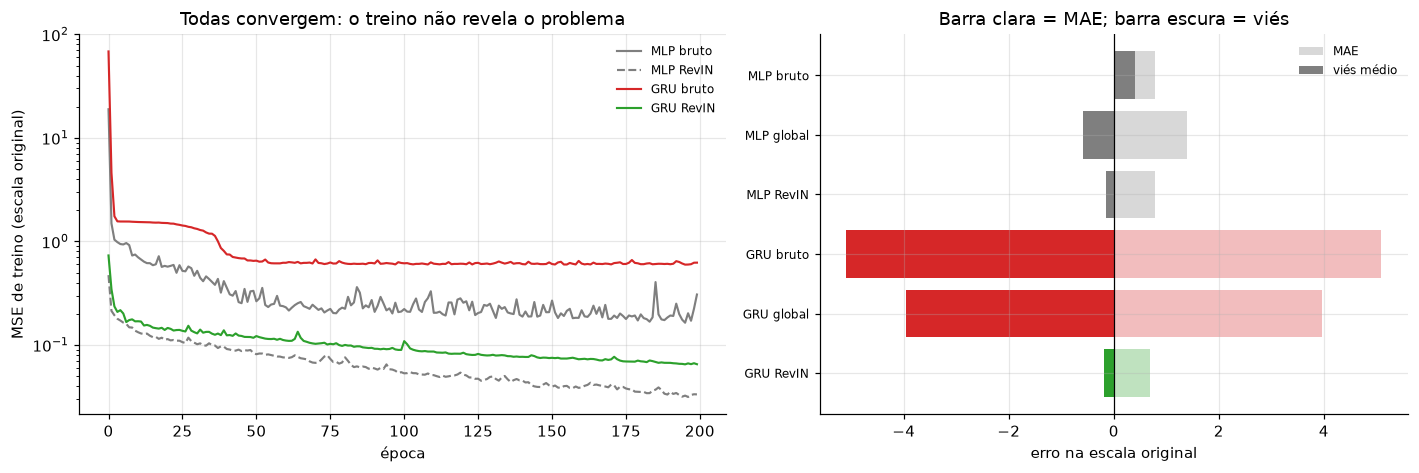

Fração do MAE que é viés (|viés| / MAE):
  MLP bruto     52.9%
  MLP global    41.7%
  MLP RevIN     18.4%
  GRU bruto    100.0%
  GRU global   100.0%
  GRU RevIN     26.5%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})

# ---- curvas de perda de treino ---------------------------------------
ax = axes[0]
for k, cor, ls in [("MLP bruto", C_CINZA, "-"), ("MLP RevIN", C_CINZA, "--"),
                   ("GRU bruto", C_TESTE, "-"), ("GRU RevIN", C_REVIN, "-")]:
    ax.plot(exp[k]["mse_hist"], color=cor, ls=ls, lw=1.4, label=k)
ax.set_yscale("log")
ax.set_xlabel("época")
ax.set_ylabel("MSE de treino (escala original)")
ax.set_title("Todas convergem: o treino não revela o problema")
ax.legend(frameon=False, fontsize=8)

# ---- MAE e viés -------------------------------------------------------
ax = axes[1]
nomes = list(exp.keys())
mae = [exp[k]["metricas"]["MAE"] for k in nomes]
vies = [exp[k]["metricas"]["Viés médio"] for k in nomes]
cores = [C_CINZA, C_CINZA, C_CINZA, C_TESTE, C_TESTE, C_REVIN]
y = np.arange(len(nomes))
ax.barh(y, mae, color=cores, alpha=0.30, label="MAE")
ax.barh(y, vies, color=cores, label="viés médio")
ax.set_yticks(y, nomes, fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("erro na escala original")
ax.set_title("Barra clara = MAE; barra escura = viés")
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

print("Fração do MAE que é viés (|viés| / MAE):")
for k in nomes:
    M = exp[k]["metricas"]
    print(f"  {k:12s} {abs(M['Viés médio']) / M['MAE']:6.1%}")

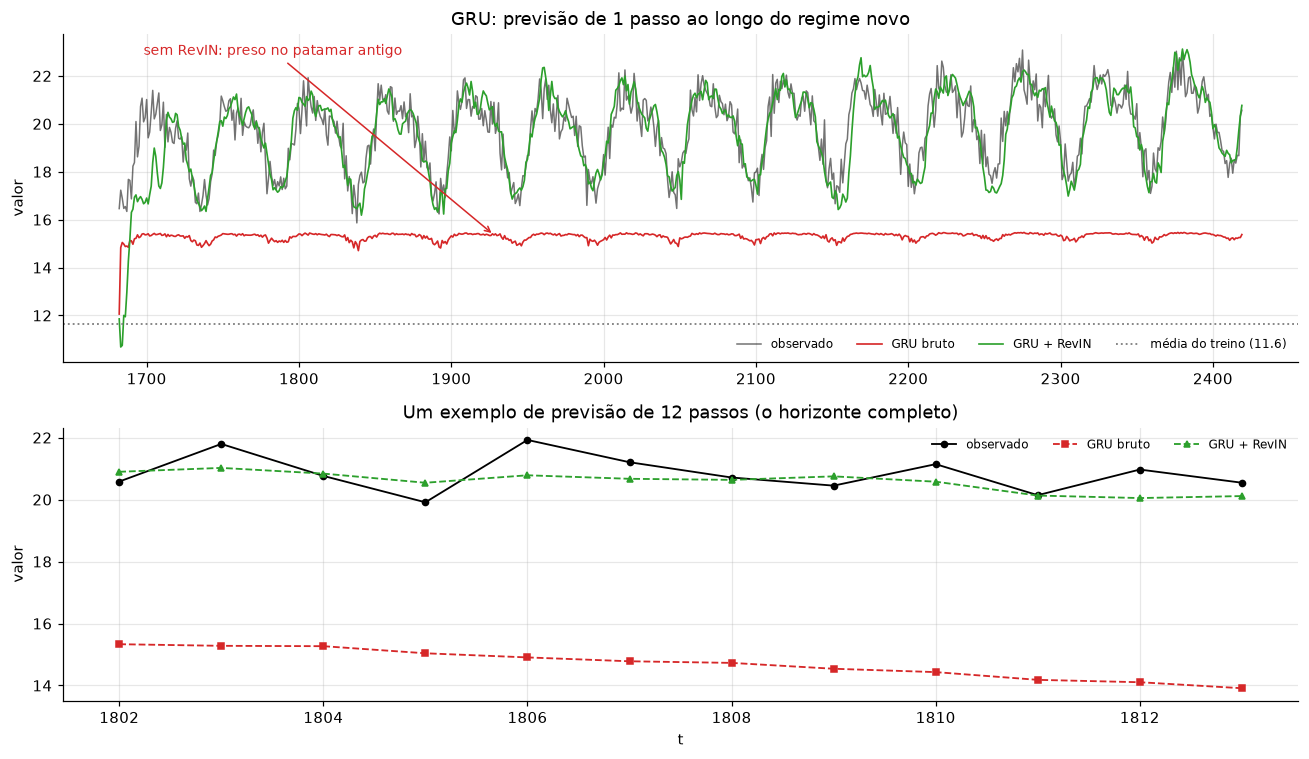

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [1.2, 1]})

# ---- previsão de 1 passo, janela a janela, ao longo do regime novo ----
ax = axes[0]
tt = test_ends + LOOKBACK
ax.plot(tt, exp["GRU RevIN"]["true"][:, 0], color="k", lw=1.0, alpha=0.55, label="observado")
ax.plot(tt, exp["GRU bruto"]["pred"][:, 0], color=C_TESTE, lw=1.1, label="GRU bruto")
ax.plot(tt, exp["GRU RevIN"]["pred"][:, 0], color=C_REVIN, lw=1.1, label="GRU + RevIN")
ax.axhline(serie[:T0].mean(), color=C_CINZA, ls=":", lw=1.2,
           label=f"média do treino ({serie[:T0].mean():.1f})")
k_an = len(tt) // 3
ax.annotate("sem RevIN: preso no patamar antigo",
            xy=(tt[k_an], exp["GRU bruto"]["pred"][k_an, 0]),
            xytext=(tt[k_an] - 230, serie[T0:].max() * 0.99),
            arrowprops=dict(arrowstyle="->", lw=1.0, color=C_TESTE),
            fontsize=9, color=C_TESTE)
ax.set_title("GRU: previsão de 1 passo ao longo do regime novo")
ax.set_ylabel("valor")
ax.legend(frameon=False, ncol=4, fontsize=8)

# ---- uma janela, horizonte completo ---------------------------------
ax = axes[1]
i = 120
tt2 = test_ends[i] + LOOKBACK + np.arange(HORIZON)
ax.plot(tt2, exp["GRU RevIN"]["true"][i], "o-", color="k", lw=1.2, ms=4, label="observado")
ax.plot(tt2, exp["GRU bruto"]["pred"][i], "s--", color=C_TESTE, lw=1.2, ms=4, label="GRU bruto")
ax.plot(tt2, exp["GRU RevIN"]["pred"][i], "^--", color=C_REVIN, lw=1.2, ms=4, label="GRU + RevIN")
ax.set_title(f"Um exemplo de previsão de {HORIZON} passos (o horizonte completo)")
ax.set_xlabel("t")
ax.set_ylabel("valor")
ax.legend(frameon=False, ncol=3, fontsize=8)

plt.tight_layout()
plt.show()

### Leitura dos resultados

**1. A GRU sem normalização colapsa, e o erro é 100% viés.** Ela não "errou por pouco": continua prevendo no patamar antigo. O erro é negativo, sistemático e não diminui com o horizonte — comportamento de uma rede saturada, que perdeu a capacidade de distinguir níveis. A normalização global melhora um pouco (as estatísticas congeladas pelo menos trazem os valores para perto de [0,1]), mas ainda é ~6× pior que o RevIN.

**2. A MLP quase não sofre — e isso é a lição mais útil do notebook.** Uma rede feedforward com ReLU e saída linear é **positivamente homogênea**: multiplicar a entrada por $a>0$ multiplica a saída por aproximadamente $a$. Os vieses quebram essa homogeneidade, mas só parcialmente. Resultado: a MLP absorve boa parte do shift "de graça", sem que ninguém tenha programado isso — e aqui ela **empata** com a versão normalizada (0,78 vs. 0,78). Note, ainda, que a normalização *global* a piora: estatísticas congeladas são piores que nenhuma normalização.

**3. Consequência prática — não conclua nada a partir de uma arquitetura só.** Se o seu primeiro teste com MLP mostrou que o RevIN "não muda muito", o teste não provou que o RevIN é dispensável; provou que essa arquitetura é acidentalmente robusta. Com um modelo recorrente, com atenção, ou com `LayerNorm` em vários pontos, o shift deixa de ser absorvido e o RevIN passa a valer 5–10× em erro. Sempre valide a camada no modelo que você vai usar em produção.

**4. As curvas de perda de treino são parecidas.** As seis configurações convergem e explicam o treino muito bem. Um `train_loss` baixo não diz nada sobre generalização sob shift: se o pipeline só monitora a perda de treino, o problema é invisível até ir para produção.

**5. Por que o erro do RevIN ainda não é zero?** Porque o shift não foi puramente afim: mudei a fase do harmônico e aumentei o ruído. Se o teste fosse exatamente $3{,}5x + 12$, o erro cairia para o nível do treino. Vale rodar essa variação (exercício 2).

## 8. O efeito cresce com o tamanho do shift

Uma pergunta óbvia: se a MLP é quase homogênea, o RevIN deixa de importar para ela quando o shift é pequeno? E a GRU piora proporcionalmente?

Para responder sem confundir as coisas, o desenho tem de ser limpo. Se eu aumentar o nível *e* o ruído ao mesmo tempo, o erro sobe por dois motivos e não dá para atribuir nada ao shift. Então aqui o regime B é uma **transformação afim exata** da mesma forma:

$$s_B(t) = k \cdot \big[\, 10 + \beta t + 3 + \text{sazonalidade}(t) + \varepsilon_t \,\big], \qquad k \in \{1;\ 1{,}6;\ 2{,}5;\ 4\}$$

Amplitude, ruído e tendência escalam juntos. Só o patamar muda.

E a métrica tem de ser **relativa**. MAE em unidades absolutas cresce com a série por construção — um modelo perfeito teria MAE × 4 quando a série cresce × 4. O que mede invariância é o **MAPE**: se o erro percentual não muda quando o regime muda, o modelo é invariante ao regime.


-- regime B = 1.0 x a forma base (média ~14 vs treino ~12) --


MLP bruto        MAE   0.33  MAPE   2.39%  viés   +0.04


MLP RevIN        MAE   0.36  MAPE   2.65%  viés   -0.01


GRU bruto        MAE   0.83  MAPE   5.88%  viés   -0.66


GRU RevIN        MAE   0.32  MAPE   2.33%  viés   -0.01

-- regime B = 1.6 x a forma base (média ~22 vs treino ~12) --


MLP bruto        MAE   0.57  MAPE   2.59%  viés   -0.09


... (7 outputs left out)

MLP bruto        MAE   1.49  MAPE   2.73%  viés   -0.02


MLP RevIN        MAE   1.93  MAPE   3.58%  viés   -0.63


GRU bruto        MAE  45.84  MAPE  83.17%  viés  -45.84


GRU RevIN        MAE   1.82  MAPE   3.37%  viés   -0.67

MAPE (%) por escala do regime B:
modelo  GRU RevIN  GRU bruto  MLP RevIN  MLP bruto
escala                                            
1.0          2.33       5.88       2.65       2.39
1.6          2.91      46.50       3.07       2.59
2.5          3.16      71.00       3.37       2.66
4.0          3.37      83.17       3.58       2.73


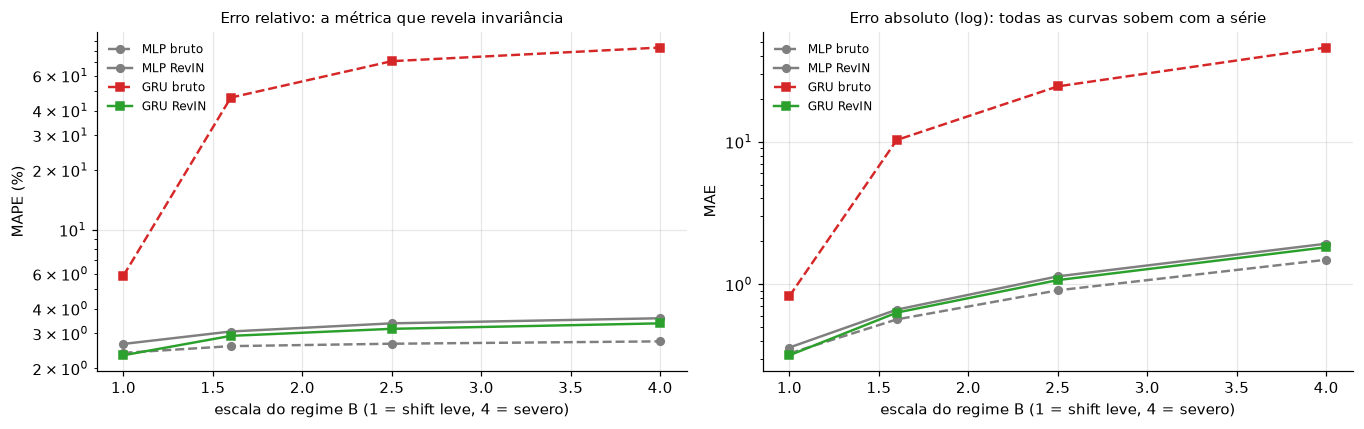

In [11]:
def make_serie_escala(escala, seed=SEED):
    """Regime B = transformação afim exata da forma base, multiplicada por `escala`.

    Escalar tudo junto (nível, tendência, ruído) garante que só o shift varia:
    a dificuldade intrínseca do problema fica constante.
    """
    g = np.random.default_rng(seed)
    base = (10.0 + 0.002 * t + 1.0 * np.sin(2 * np.pi * t / 52)
            + 0.4 * np.sin(2 * np.pi * t / 26 + 1.0) + g.normal(0, 0.30, N))
    forma_b = (1.0 * np.sin(2 * np.pi * t[T0:] / 52 + 0.25)
               + 0.4 * np.sin(2 * np.pi * t[T0:] / 26 + 1.35)
               + g.normal(0, 0.30, N - T0))
    s = base.copy()
    s[T0:] = escala * (10.0 + 0.002 * (t[T0:] - T0) + 3.0 + forma_b)
    return s


resultados_sweep = []
for k in [1.0, 1.6, 2.5, 4.0]:
    s = make_serie_escala(k)
    print(f"\n-- regime B = {k:.1f} x a forma base (média ~{s[T0:].mean():.0f} vs treino ~{s[:T0].mean():.0f}) --")
    for nome, ctor in [("MLP bruto", lambda: MLPForecaster(LOOKBACK, HORIZON)),
                       ("MLP RevIN", lambda: MLPForecaster(LOOKBACK, HORIZON, use_revin=True)),
                       ("GRU bruto", lambda: GRUForecaster(HORIZON)),
                       ("GRU RevIN", lambda: GRUForecaster(HORIZON, use_revin=True))]:
        r = experimento(nome, s, ctor, epochs=120)
        resultados_sweep.append({"escala": k, "modelo": nome, **r["metricas"]})

sweep = pd.DataFrame(resultados_sweep)
piv = sweep.pivot(index="escala", columns="modelo", values="MAPE (%)").astype(float)
print("\nMAPE (%) por escala do regime B:")
print(piv.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), sharex=True)
estilos = {"MLP bruto": (C_CINZA, "o--"), "MLP RevIN": (C_CINZA, "o-"),
           "GRU bruto": (C_TESTE, "s--"), "GRU RevIN": (C_REVIN, "s-")}
for ax, col, titulo in [(axes[0], "MAPE (%)", "Erro relativo: a métrica que revela invariância"),
                        (axes[1], "MAE", "Erro absoluto (log): todas as curvas sobem com a série")]:
    p = sweep.pivot(index="escala", columns="modelo", values=col).astype(float)
    for nome, (cor, mk) in estilos.items():
        ax.plot(p.index, p[nome], mk, color=cor, lw=1.6, ms=5, label=nome)
    ax.set_xlabel("escala do regime B (1 = shift leve, 4 = severo)")
    ax.set_title(titulo, fontsize=10)
    ax.set_yscale("log")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("MAPE (%)")
axes[1].set_ylabel("MAE")
plt.tight_layout()
plt.show()

### O que o sweep mostra

**Painel esquerdo (MAPE, a métrica que importa):**

* **GRU bruta:** 6% → 83%. Cresce monotonicamente e satura no absurdo. O modelo não "piora um pouco": ele desliga.
* **GRU + RevIN:** 2,3% → 3,4%. Sobe um terço, num gráfico onde a outra curva multiplica por 14. É a definição operacional de invariância ao regime.
* **MLP bruta:** também plana — a quase-homogeneidade em ação, sem nenhum código de normalização.
* **MLP + RevIN:** plana, mas **um pouco acima** da MLP bruta. Não há almoço grátis: para uma arquitetura que já consegue usar o nível a seu favor, a normalização impõe uma restrição que custa alguns décimos de ponto percentual.

**Painel direito (MAE):** todas as curvas sobem, inclusive a das configurações normalizadas. Isso não é falha do RevIN — é a série ficando maior. Confundir os dois painéis é um dos erros mais comuns em *benchmark* de previsão.

### A conclusão que interessa

O RevIN não é um "melhorador de acurácia". É um **removedor de dependência do regime**. O critério para adotá-lo não é "o MAE caiu no meu teste?", e sim:

> O erro do meu modelo muda quando o nível da série muda? Se sim, o RevIN resolve. Se não, ele é neutro (ou levemente negativo).

Nas duas arquiteturas testadas, o resultado é exatamente esse: decisivo na GRU, neutro na MLP. Levar a camada para produção sem fazer essa pergunta é como comprar remédio sem saber a doença.

## 9. O que o RevIN realmente vê

Se calcularmos, para cada janela, a média e o desvio da entrada, elas rastreiam o regime. É essa informação que o modelo passa a não precisar aprender — e que, sem normalização, ele teria de aprender de um jeito que não se transfere para outro patamar.

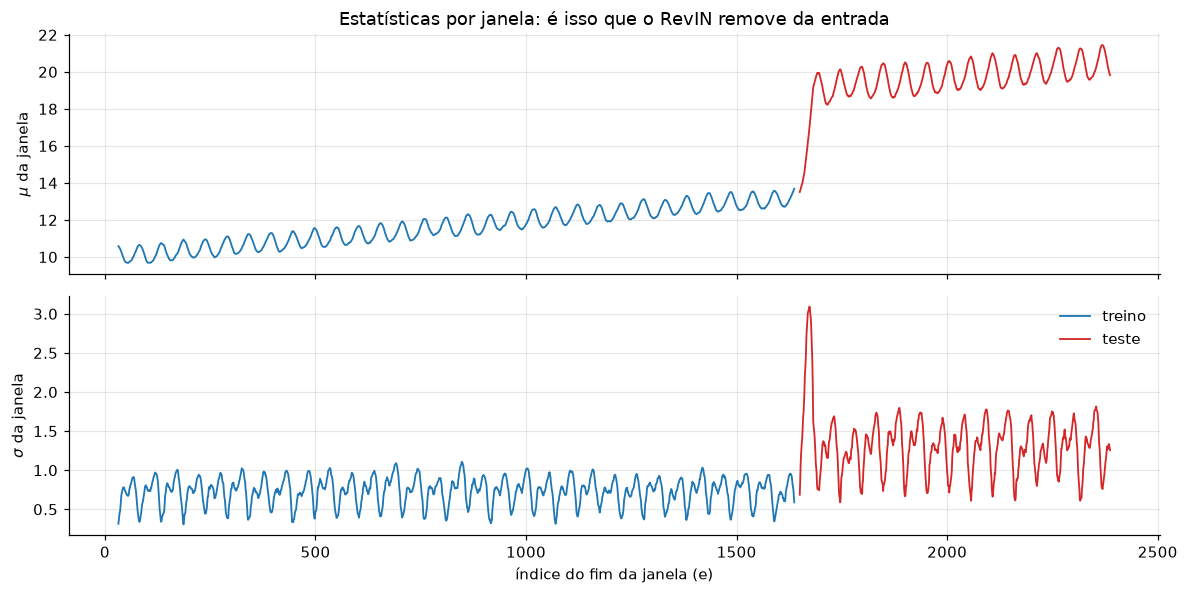

mu   : treino 11.62  ->  teste 19.60   (razão 1.69x)
sigma: treino 0.73  ->  teste 1.32   (razão 1.81x)

O modelo normalizado vê a mesma distribuição nos dois regimes; o bruto vê outra.


In [12]:
medias = np.array([serie[e - LOOKBACK:e].mean() for e in train_ends])
desvios = np.array([serie[e - LOOKBACK:e].std() for e in train_ends])
medias_te = np.array([serie[e - LOOKBACK:e].mean() for e in test_ends])
desvios_te = np.array([serie[e - LOOKBACK:e].std() for e in test_ends])

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(train_ends, medias, color=C_TREINO, lw=1.2)
axes[0].plot(test_ends, medias_te, color=C_TESTE, lw=1.2)
axes[0].set_ylabel(r"$\mu$ da janela")
axes[0].set_title("Estatísticas por janela: é isso que o RevIN remove da entrada")

axes[1].plot(train_ends, desvios, color=C_TREINO, lw=1.2, label="treino")
axes[1].plot(test_ends, desvios_te, color=C_TESTE, lw=1.2, label="teste")
axes[1].set_ylabel(r"$\sigma$ da janela")
axes[1].set_xlabel("índice do fim da janela (e)")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"mu   : treino {medias.mean():.2f}  ->  teste {medias_te.mean():.2f}   "
      f"(razão {medias_te.mean()/medias.mean():.2f}x)")
print(f"sigma: treino {desvios.mean():.2f}  ->  teste {desvios_te.mean():.2f}   "
      f"(razão {desvios_te.mean()/desvios.mean():.2f}x)")
print("\nO modelo normalizado vê a mesma distribuição nos dois regimes; o bruto vê outra.")

## 10. A variante `affine`: vale a pena?

O artigo propõe $\gamma$ e $\beta$ aprendíveis, que dão ao modelo liberdade para desfazer parte da padronização (por exemplo, se a série tem tendência forte dentro da janela, talvez não valha centralizar exatamente em zero).

Na prática, **`affine=False` costuma ser mais robusto quando o regime de teste é muito diferente do treino**, porque não há parâmetros extras para sobreajustar ao treino — mas a diferença costuma ser pequena. Meça; não acredite.

In [13]:
r_aff = experimento("GRU RevIN aff=F", serie, lambda: GRUForecaster(HORIZON, use_revin=True, affine=False))
exp["GRU RevIN aff=False"] = r_aff

m = GRUForecaster(HORIZON, use_revin=True, affine=True)
print("\ngamma e beta iniciais (identidade):", m.revin.gamma.item(), m.revin.beta.item())
print("durante o treino eles só saem da identidade se isso reduzir a perda na escala original.")

GRU RevIN aff=F  MAE   0.70  MAPE   3.59%  viés   -0.18

gamma e beta iniciais (identidade): 1.0 0.0
durante o treino eles só saem da identidade se isso reduzir a perda na escala original.


## 11. Bônus: RevIN + regressão linear

Se o RevIN é a peça que importa, um modelo trivial deveria ficar competitivo. É o que Zeng et al. (2023) mostraram: **DLinear = RevIN + uma camada linear**, e essa combinação bate Transformers em vários benchmarks de longo horizonte.

O ponto não é "rede neural é ruim". É que boa parte do ganho atribuído a arquiteturas complexas vinha de **normalização e formulação do problema**, não de capacidade representacional. Rode esse baseline *antes* de investir em atenção.

In [14]:
class LinearRevIN(nn.Module):
    """NLinear/DLinear simplificado: RevIN + projeção linear."""

    def __init__(self, lookback, horizon):
        super().__init__()
        self.revin = RevIN(1, affine=False)
        self.lin = nn.Linear(lookback, horizon)

    def forward(self, x):
        x = self.revin.normalize(x)
        y = self.lin(x.squeeze(-1)).unsqueeze(-1)
        return self.revin.denormalize(y)


exp["Linear RevIN"] = experimento("Linear RevIN", serie, lambda: LinearRevIN(LOOKBACK, HORIZON))

print("\n== Tabela final (teste no regime B) ==")
final = pd.DataFrame({k: v["metricas"] for k, v in exp.items()}).T
final = final[["MAE", "RMSE", "MAPE (%)", "Viés médio"]].sort_values("MAE")
print(final.round(2).to_string())
print(f"\nparâmetros — MLP: {sum(p.numel() for p in MLPForecaster(LOOKBACK, HORIZON).parameters())}, "
      f"GRU: {sum(p.numel() for p in GRUForecaster(HORIZON).parameters())}, "
      f"linear: {sum(p.numel() for p in LinearRevIN(LOOKBACK, HORIZON).parameters())}")

Linear RevIN     MAE   0.82  MAPE   4.20%  viés   +0.02

== Tabela final (teste no regime B) ==
                      MAE  RMSE  MAPE (%)  Viés médio
GRU RevIN            0.69  1.01      3.51       -0.18
GRU RevIN aff=False  0.70  1.02      3.59       -0.18
MLP bruto            0.78  1.00      4.04        0.41
MLP RevIN            0.78  1.06      4.03       -0.14
Linear RevIN         0.82  1.09      4.20        0.02
MLP global           1.39  1.68      7.06       -0.58
GRU global           3.96  4.23     19.63       -3.96
GRU bruto            5.09  5.32     25.33       -5.09

parâmetros — MLP: 22284, GRU: 13644, linear: 396


## 12. Armadilhas — a parte que evita retrabalho

**1. Estatísticas calculadas sobre a janela errada.** O erro clássico é normalizar a série inteira (treino + teste) antes de dividir. Isso vaza a média do futuro para o passado e infla o desempenho. Com RevIN isso desaparece por construção — mas se você pré-normalizar "por fora" *e* ainda usar RevIN, está fazendo duas coisas e testando nenhuma.

**2. `denormalize` com as estatísticas de outra amostra.** Uma única instância de `RevIN` guarda `_mean/_std` da última chamada. Se você processar o batch A, depois o B, e desnormalizar A com o estado de B, o resultado é silenciosamente errado — sem exceção, sem `NaN`. Com múltiplos forwards intercalados, isso acontece de verdade.

**3. RevIN remove nível e escala, não tendência.** Se a janela tem inclinação, ela continua lá depois de normalizada (em unidades de $\sigma$ por passo). Para séries com tendência forte dentro da janela, combine com diferenciação ou use o `subtract_last` do artigo. Não presuma que o RevIN "estacionariza" a série.

**4. RevIN não corrige mudança de forma.** Se o regime novo tem outra sazonalidade, outro padrão semanal, ou um patamar que muda *durante* o horizonte, nenhuma transformação afim por janela resolve. O erro residual do experimento acima é exatamente isso.

**5. Perda na escala errada.** Otimizar no espaço normalizado versus na escala original muda o que o modelo otimiza (erro relativo vs. absoluto). Escolha deliberadamente e documente se o RevIN está dentro ou fora do modelo na hora de calcular a perda.

**6. Séries com zeros ou patamares constantes.** Sem `eps`, `var=0` gera divisão por zero ou `inf` que se propaga como `NaN` silencioso duas épocas depois. O `1e-5` não é decoração.

**7. Múltiplos canais.** Se o alvo é multivariado (demanda de etanol *e* gasolina, digamos), cada canal tem seu próprio $\mu, \sigma, \gamma, \beta$. Normalizar todos com as estatísticas do alvo é um erro comum e difícil de detectar — as dimensões têm ordens de grandeza diferentes.

**8. Comparação desonesta.** Baselines sem RevIN precisam da mesma arquitetura, mesmas épocas e mesma semente. Baseline mal treinado mede o seu esforço de tuning, não o efeito da normalização.

**9. Concluir a partir de uma arquitetura.** É a lição deste notebook: MLP não sofre, GRU colapsa. Teste no modelo que vai para produção.

## 13. Onde isso se encaixa na literatura e no seu caso

| Trabalho | Contribuição relevante aqui |
|---|---|
| Kim et al., **RevIN**, ICLR 2022 | propõe a normalização por instância com inverso e o `affine`; vira camada padrão de previsores neurais |
| Zeng et al., **DLinear/NLinear**, AAAI 2023 | RevIN + linear competitivo com Transformers; argumento forte contra complexidade desnecessária |
| Nie et al., **PatchTST**, ICLR 2023 | adota RevIN como componente padrão em previsão de longo horizonte |
| Zeng et al., **Informer/Autoformer** e linhagem | motivam a linha de *long-term forecasting*, onde o shift de distribuição é o problema dominante |

**Conexão com previsão de longo horizonte de etanol:** se a série tem quebras de patamar (política de preços, mudança tributária, choque cambial), o RevIN é provavelmente a intervenção de maior retorno por linha de código — maior, inclusive, que trocar MLP por TFT. E é compatível com qualquer arquitetura: TFT, NARX, DA-RNN ou mesmo um ARIMA com regressores, aplicado como pré/pós-processamento.

Uma dose de honestidade: em séries com coeficiente de Hurst próximo de 0,5 e sem estrutura sazonal, o ganho do RevIN tende a ser **de robustez a quebras**, não de acurácia em regime estável. Ele evita o desastre; não cria sinal onde não há.

## 14. Exercícios

1. **Quebre o RevIN de propósito.** Troque `dim=1` por `dim=0` em `normalize`. Rode o experimento e explique o resultado. (Dica: `dim=0` normaliza o batch, e o modelo perde a informação de nível de cada amostra — inclusive a que ele usava para acertar.)
2. **Shift puramente afim.** Gere o regime B como `3.5 * regime_A + 12`. Rode as configurações. O MAE normalizado deve cair para o patamar de treino e o bruto deve continuar errado. Explique por quê.
3. **Horizonte.** Repita com `HORIZON = 36`. Faça o gráfico de MAE vs. horizonte para as quatro configurações. O erro cresce para todos (extrapolação), mas o *viés* só existe nas não normalizadas.
4. **Retreino ingênuo.** Em vez de RevIN, retreine a GRU com os primeiros 200 pontos do regime B. Quanto dado novo é necessário para igualar o RevIN? E o que acontece nos 200 primeiros pontos, antes de haver dado?
5. **Série real.** Aplique ao seu caso: escolha uma série com quebra visível, compare `global` e `revin` com `LinearRevIN` como baseline, e monitore o **viés médio por janela** — é o diagnóstico mais informativo e o mais ignorado.
6. **Variante `subtract_last`.** Implemente a opção do artigo que subtrai o último valor em vez da média (útil para séries com tendência) e compare com a versão padrão.

## Referências

- Kim, T., Kim, J., Tae, Y., Park, C., Choi, J.-H., Choo, J. *Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift.* ICLR, 2022.
- Zeng, A., Chen, M., Zhang, L., Xu, Q. *Are Transformers Effective for Time Series Forecasting?* AAAI, 2023.
- Nie, Y., Nguyen, N. H., Sinthong, P., Kalagnanam, J. *A Time Series is Worth 64 Words: Long-term Forecasting with Transformers.* ICLR, 2023.
- Hyndman, R. J., Athanasopoulos, G. *Forecasting: Principles and Practice.* OTexts, 2021 — capítulos sobre transformações e normalização.